In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Load dataset
df = pd.read_csv("../data/raw/california_housing.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
# First 5 rows
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 20640
Columns: 9


In [4]:
# Column information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [6]:
# Missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [7]:
# Duplicate records
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


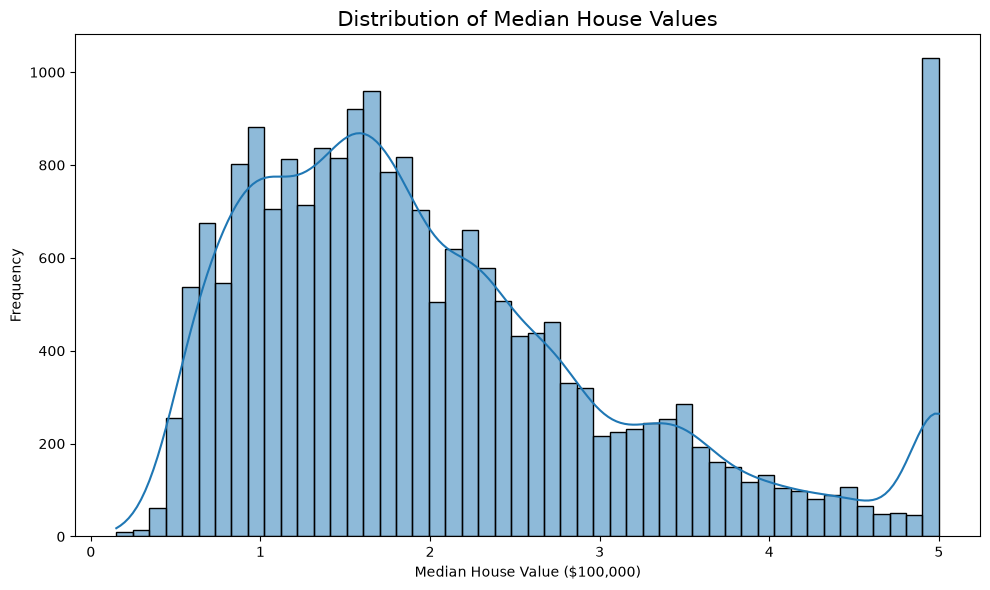

In [14]:
# House Price Distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    df["MedHouseVal"],
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Values", fontsize=15)
plt.xlabel("Median House Value ($100,000)")
plt.ylabel("Frequency")

plt.tight_layout(
)
plt.savefig(
    FIGURES_DIR / "house_price_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

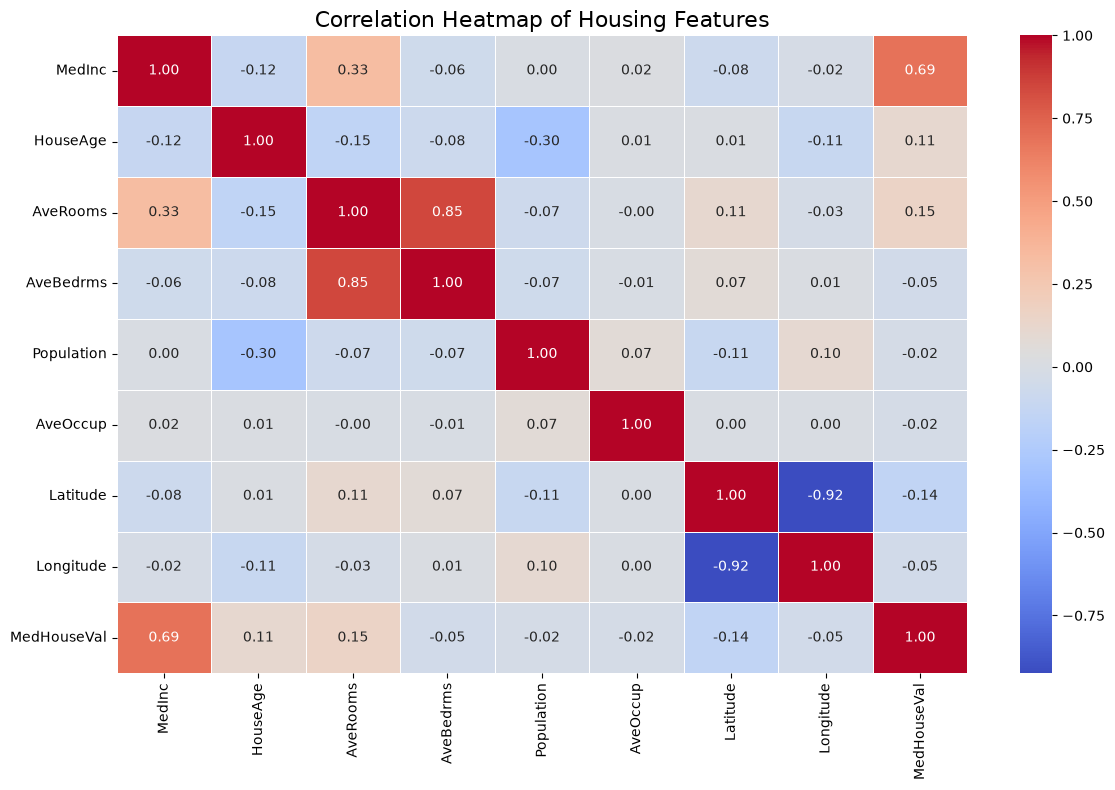

In [15]:
# Correlation Heatmap

plt.figure(figsize=(12, 8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Housing Features", fontsize=16)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

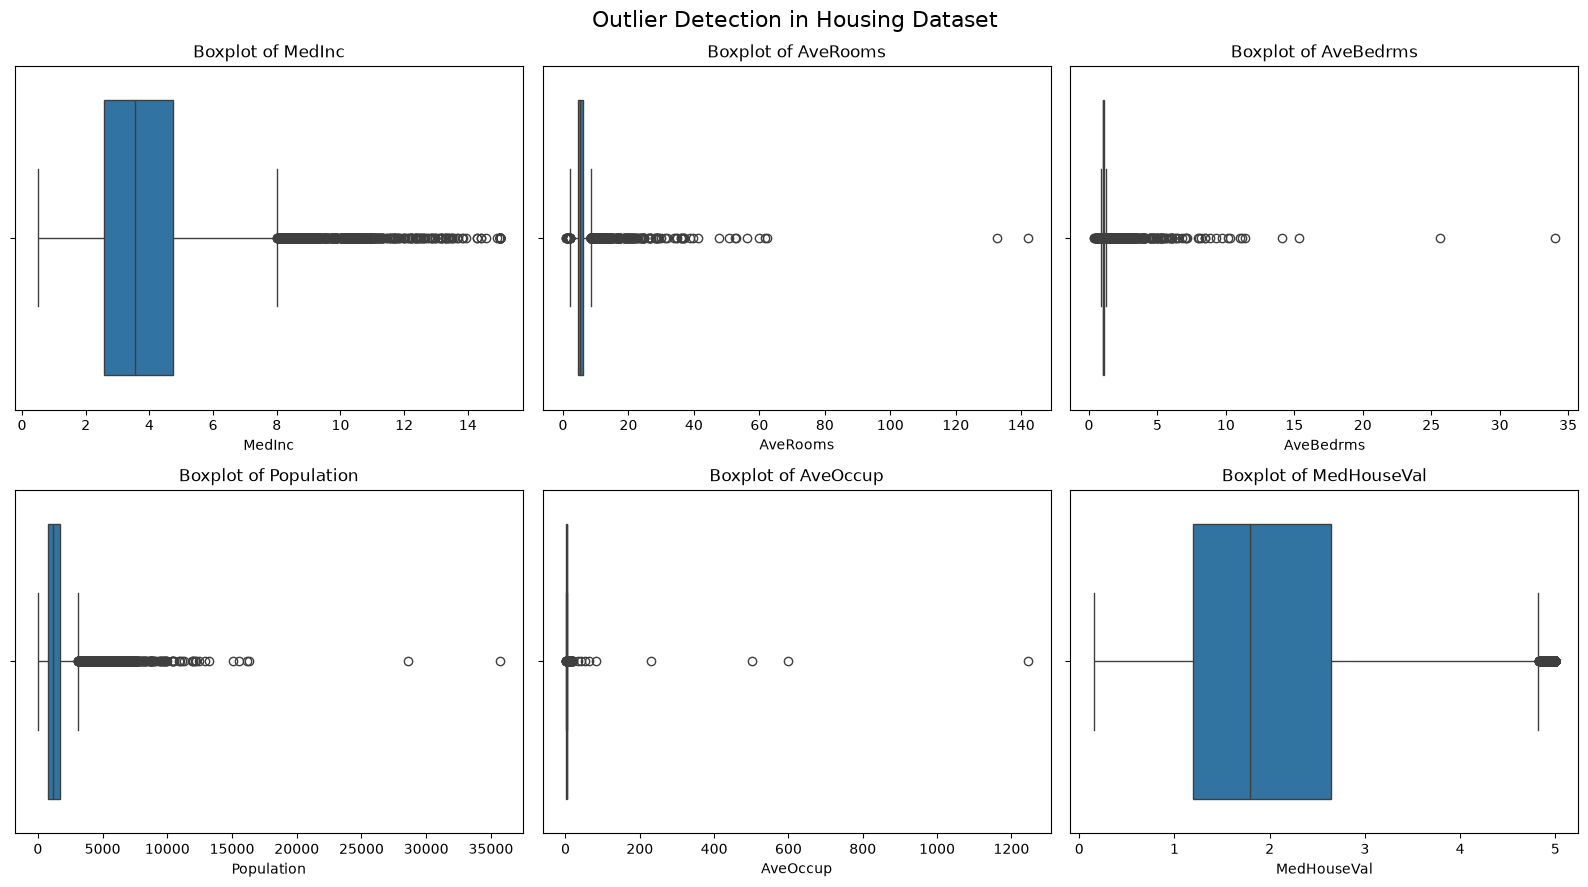

In [16]:
# Outlier Detection using Boxplots

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

features = [
    "MedInc",
    "AveRooms",
    "AveBedrms",
    "Population",
    "AveOccup",
    "MedHouseVal"
]

for ax, feature in zip(axes.flatten(), features):
    sns.boxplot(x=df[feature], ax=ax)
    ax.set_title(f"Boxplot of {feature}")

plt.suptitle("Outlier Detection in Housing Dataset", fontsize=16)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "outlier_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
# Outlier Detection using IQR Method

features = [
    "MedInc",
    "AveRooms",
    "AveBedrms",
    "Population",
    "AveOccup",
    "MedHouseVal"
]

outlier_results = []

for feature in features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_limit) |
        (df[feature] > upper_limit)
    ]

    outlier_results.append({
        "Feature": feature,
        "Lower Limit": round(lower_limit, 2),
        "Upper Limit": round(upper_limit, 2),
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,Feature,Lower Limit,Upper Limit,Outlier Count,Outlier Percentage
0,MedInc,-0.71,8.01,681,3.30
1,AveRooms,2.02,8.47,511,2.48
2,AveBedrms,0.87,1.24,1424,6.90
3,Population,-620.00,3132.00,1196,5.79
4,AveOccup,1.15,4.56,711,3.44
5,MedHouseVal,-0.98,4.82,1071,5.19


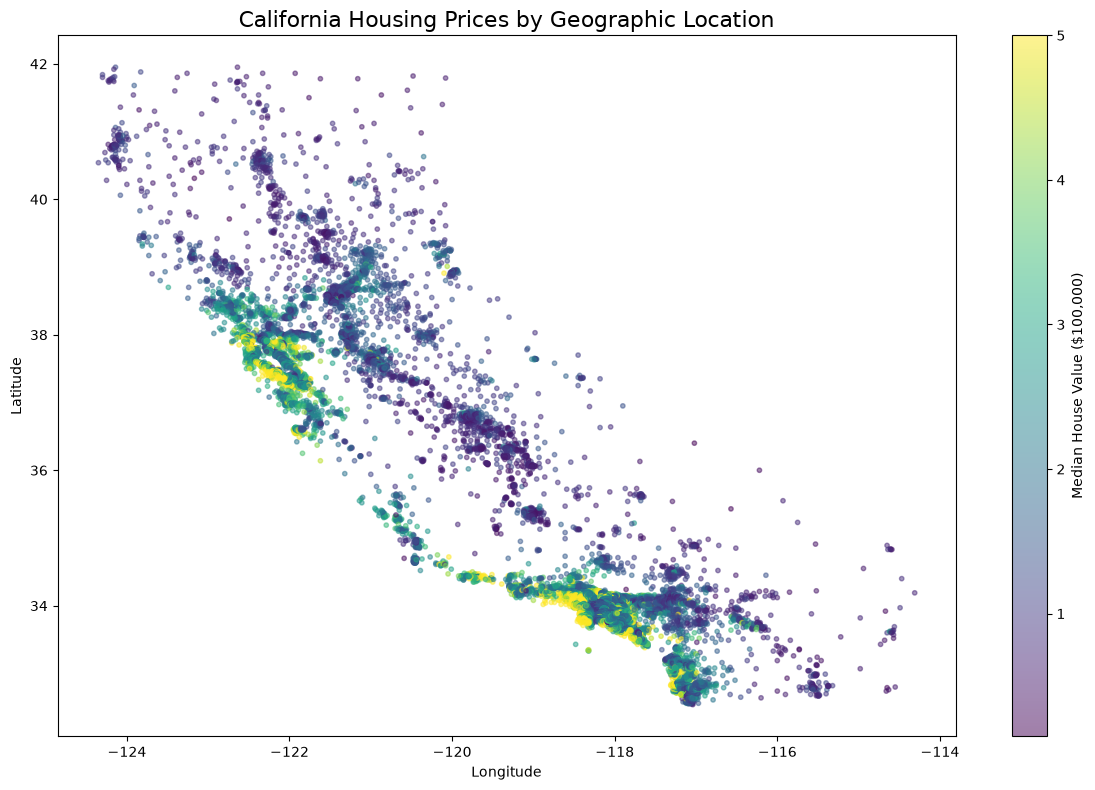

In [17]:
# Geographical Analysis of House Prices

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["MedHouseVal"],
    cmap="viridis",
    alpha=0.5,
    s=10
)

plt.colorbar(
    scatter,
    label="Median House Value ($100,000)"
)

plt.title(
    "California Housing Prices by Geographic Location",
    fontsize=16
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "geographical_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Exploratory Data Analysis (EDA) - Key Findings

1. Dataset contains 20,640 records and 9 numerical columns.
2. No missing values or duplicate records were found.
3. Median income has the strongest positive correlation (0.69) with house values.
4. Average rooms and average bedrooms show strong correlation (0.85).
5. The target variable is right-skewed.
6. House values show a noticeable cap near 5.0.
7. IQR analysis identified potential outliers in multiple features.
8. Geographical analysis helps identify regional patterns in California housing prices.

## EDA Conclusion

Median income appears to be an important predictor of house values. 
Geographical location and other housing characteristics may also 
contribute to prediction performance. Further investigation will be 
performed during feature engineering and model development.

In [13]:
from pathlib import Path

FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Figures folder created successfully!")

Figures folder created successfully!


In [18]:
print("Saved Visualization Files:")

for file in FIGURES_DIR.glob("*.png"):
    print(file.name)

Saved Visualization Files:
correlation_heatmap.png
geographical_analysis.png
house_price_distribution.png
outlier_analysis.png
